## IN4050 Mandatory Assignment 2, 2026: Supervised Learning

### Rules

Before you begin the exercise, review the rules at this website: https://www.uio.no/english/studies/examinations/compulsory-activities/mn-ifi-mandatory.html , in particular the paragraph on cooperation. This is an individual assignment. You are not allowed to deliver together or copy/share source-code/answers with others. Read also the "Routines for handling suspicion of cheating and attempted cheating at the University of Oslo": https://www.uio.no/english/studies/examinations/cheating/index.html By submitting this assignment, you confirm that you are familiar with the rules and the consequences of breaking them. See also https://www.uio.no/english/studies/resources/ai_student.html for guidelines on how to use AI as a student, which you are required to follow.

### Delivery

**Deadline**: October 27, 2026, 23:59

Your submission should be delivered in Devilry. You may redeliver in Devilry before the deadline, but include all files in the last delivery, as only the last delivery will be read. You are recommended to upload preliminary versions hours (or days) before the final deadline.

### What to deliver?

You are recommended to solve the exercise in a Jupyter notebook, but you might solve it in a regular Python script if you prefer.

#### Alternative 1
If you prefer not to use notebooks, you should deliver the code, your run results, and a PDF report where you answer all the questions and explain your work.

#### Alternative 2
If you choose Jupyter, you should deliver the notebook. You should answer all questions and explain what you are doing in Markdown. Still, the code should be properly commented. The notebook should contain results of your runs. In addition, you should make a pdf of your solution which shows the results of the runs. (If you can't export: notebook -> latex -> pdf on your own machine, you may do this on the IFI linux machines.)

Here is a list of *absolutely necessary* (but not sufficient) conditions to get the assignment marked as passed:

- You must deliver your code (Python script or Jupyter notebook) you used to solve the assignment.
- The code used for making the output and plots must be included in the assignment. 
- You must include example runs that clearly shows how to run all implemented functions and methods.
- All the code (in notebook cells or python main-blocks) must run. If you have unfinished code that crashes, please comment it out and document what you think causes it to crash. 
- You must also deliver a pdf of the code, outputs, comments and plots as explained above.

Your report/notebook should contain your name and username.

Deliver one single compressed folder (.zip, .tgz or .tar.gz) which contains your complete solution.

Important: if you weren’t able to finish the assignment, use the PDF report/Markdown to elaborate on what you’ve tried and what problems you encountered. Students who have made an effort and attempted all parts of the assignment will get a second chance even if they fail initially. This exercise will be graded PASS/FAIL.


Press "Run ALl"

My name is Zejing Wang

And my username is zejingw


### Goals of the assignment
The goal of this assignment is to get a better understanding of supervised learning with gradient descent. It will, in particular, consider the similarities and differences between linear classifiers and multi-layer feed forward neural networks (multi-layer perceptrons, MLP) and the differences and similarities between binary and multi-class classification. A significant part is dedicated to implementing and understanding the backpropagation algorithm. 

### Tools
The aim of the exercises is to give you a look inside the learning algorithms. You may freely build on code from this year's lecture notebooks (in particular Lectures 04, 07 and 08). You should not use machine learning libraries like Scikit-Learn or PyTorch, because the point of this assignment is for you to implement things from scratch. You, however, are encouraged to use tools like NumPy and Pandas, which are not ML-specific.

The given precode uses NumPy. You are recommended to use NumPy since it results in more compact code, but feel free to use pure Python if you prefer. 

### Beware
This is a revised assignment compared to earlier years. If anything is unclear, do not hesitate to ask. Also, if you think some assumptions are missing, make your own and explain them!

### Initialization

In [114]:
import numpy as np
import matplotlib.pyplot as plt
import sklearn # This is only to generate a dataset

## Datasets

We start by making a synthetic dataset of 2000 instances and five classes, with 400 instances in each class. (See https://scikit-learn.org/stable/modules/generated/sklearn.datasets.make_blobs.html regarding how the data are generated.) We choose to use a synthetic dataset---and not a set of natural occuring data---because we are mostly interested in properties of the various learning algorithms, in particular the differences between linear classifiers and multi-layer neural networks together with the difference between binary and multi-class data. In addition, we would like a dataset with instances represented with only two numerical features, so that it is easy to visualize the data. It would be rather difficult (although not impossible) to find a real-world dataset of the same nature. Anyway, you surely can use the code in this assignment for training machine learning models on real-world datasets.

When we are doing experiments in supervised learning, and the data are not already split into training and test sets, we should start by splitting the data. Sometimes there are natural ways to split the data, say training on data from one year and testing on data from a later year, but if that is not the case, we should shuffle the data randomly before splitting. (OK, that is not necessary with this particular synthetic data set, since it is already shuffled by default by Scikit-Learn, but that will not be the case with real-world data) We should split the data so that we keep the alignment between X (features) and t (class labels), which may be achieved by shuffling the indices. We split into 50% for training, 25% for validation, and 25% for final testing. The set for final testing *must not be used* till the end of the assignment in part 3.

We fix the seed both for data set generation and for shuffling, so that we work on the same datasets when we rerun the experiments. This is done by the `random_state` argument and the `rng = np.random.RandomState(2024)`.

In [115]:
# Generating the dataset
from sklearn.datasets import make_blobs
X, t_multi = make_blobs(n_samples=[400, 400, 400, 400, 400], centers=[[0,1],[4,2],[8,1],[2,0],[6,0]], 
                  n_features=2, random_state=2024, cluster_std=[1.0, 2.0, 1.0, 0.5, 0.5])

In [116]:
# Shuffling the dataset
indices = np.arange(X.shape[0])
rng = np.random.RandomState(2024)
rng.shuffle(indices)
indices[:10]

array([ 937, 1776,  868, 1282, 1396,  147,  601, 1193, 1789,  547])

In [117]:
# Splitting into train, dev and test
X_train = X[indices[:1000],:]
X_val = X[indices[1000:1500],:]
X_test = X[indices[1500:],:]
t_multi_train = t_multi[indices[:1000]]
t_multi_val = t_multi[indices[1000:1500]]
t_multi_test = t_multi[indices[1500:]]

Next, we will  make a second dataset with only two classes by merging the existing labels in (X,t), so that `0`, `1` and `2` become the new `0` and `3` and `4` become the new `1`. Let's call the new set (X, t2). This will be a binary set.
We now have two datasets:

- Binary set: `(X, t2)`
- Multi-class set: `(X, t_multi)`

In [118]:
t2_train = t_multi_train >= 3
t2_train = t2_train.astype('int')
t2_val = (t_multi_val >= 3).astype('int')
t2_test = (t_multi_test >= 3).astype('int')

We can plot the two traning sets.

Text(0.5, 1.0, 'Multi-class set')

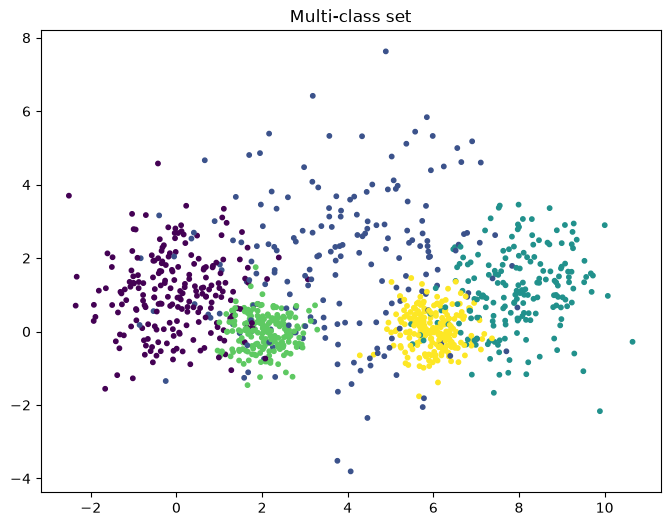

In [119]:
plt.figure(figsize=(8,6)) # You may adjust the size
plt.scatter(X_train[:, 0], X_train[:, 1], c=t_multi_train, s=10.0)
plt.title("Multi-class set")

Text(0.5, 1.0, 'Binary set')

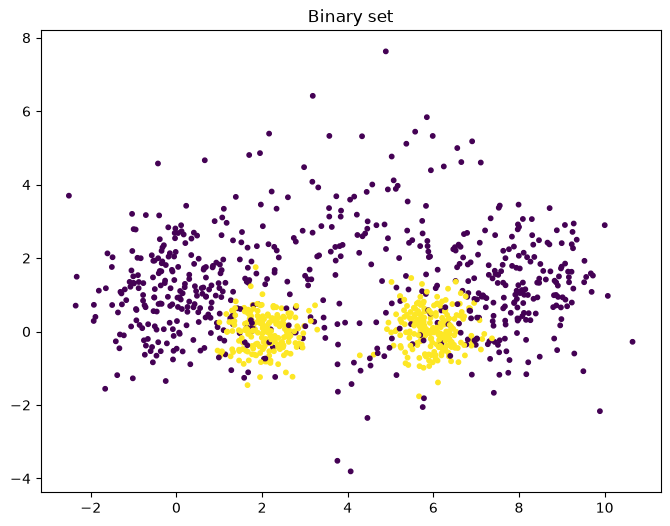

In [120]:
plt.figure(figsize=(8,6))
plt.scatter(X_train[:, 0], X_train[:, 1], c=t2_train, s=10.0)
plt.title("Binary set")

# Part 1: Linear classifiers
### Linear regression

We see that even the binary set (X, t2) is far from linearly separable, and we will explore how various classifiers are able to handle this. We start with linear regression with the Mean Squared Error (MSE) loss, although it is not the most widely used approach for classification tasks: but we are interested. The classifier below is similar to the gradient descent for linear regression from Lecture 04 (`Lecture_04_Perceptron_Linear_Regression/02_practice_perceptron_linear_regression.ipynb`, Exercise 9), written for several features at once as in Exercise 12.

In [121]:
def add_bias(X, bias):
    """X is a NxM matrix: N datapoints, M features
    bias is a bias term, -1 or 1, or any other scalar. Use 0 for no bias
    Return a Nx(M+1) matrix with added bias in position zero
    """
    N = X.shape[0]
    biases = np.ones((N, 1)) * bias # Make a N*1 matrix of biases
    # Concatenate the column of biases in front of the columns of X.
    return np.concatenate((biases, X), axis  = 1) 

In [122]:
class NumpyClassifier():
    """Common methods to all Numpy classifiers --- if any"""

In [123]:
class NumpyLinRegClass(NumpyClassifier):

    def __init__(self, bias=-1):
        self.bias=bias

    def fit(self, X_train, t_train, lr = 0.1, epochs=10):
        """X_train is a NxM matrix, N data points, M features
        t_train is avector of length N,
        the target class values for the training data
        lr is our learning rate
        """

        if self.bias:
            X_train = add_bias(X_train, self.bias)

        (N, M) = X_train.shape

        self.w = np.zeros(M)

        for epoch in range(epochs):
            # print("Epoch", epoch)
            prediction = X_train @ self.w
            error = prediction - t_train
            self.w -= lr / N * X_train.T @ error

    def predict(self, X, threshold=0.5):
        """X is a KxM matrix for some K>=1
        predict the value for each point in X"""
        if self.bias:
            X = add_bias(X, self.bias)
        ys = X @ self.w
        return ys > threshold

We can train and test a first classifier.

In [124]:
def accuracy(predicted, gold):
    return np.mean(predicted == gold)

In [125]:
cl = NumpyLinRegClass()
cl.fit(X_train, t2_train, epochs=3)
print("Accuracy on the validation set:", accuracy(cl.predict(X_val), t2_val))

Accuracy on the validation set: 0.58


The following is a small procedure which plots the data set together with the decision boundaries. 
You may modify the colors and the rest of the graphics as you like.
The procedure will also work for multi-class classifiers

In [126]:
def plot_decision_regions(X, t, clf=[], size=(8,6)):
    """Plot the data set (X,t) together with the decision boundary of the classifier clf"""
    # The region of the plane to consider determined by X
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    
    # Make a prediction of the whole region
    h = 0.02  # step size in the mesh
    xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))
    Z = clf.predict(np.c_[xx.ravel(), yy.ravel()])
    # Classify each meshpoint.
    Z = Z.reshape(xx.shape)

    plt.figure(figsize=size) # You may adjust this

    # Put the result into a color plot
    plt.contourf(xx, yy, Z, alpha=0.2, cmap = 'Paired')

    plt.scatter(X[:,0], X[:,1], c=t, s=10.0, cmap='Paired')

    plt.xlim(xx.min(), xx.max())
    plt.ylim(yy.min(), yy.max())
    plt.title("Decision regions")
    plt.xlabel("x0")
    plt.ylabel("x1")

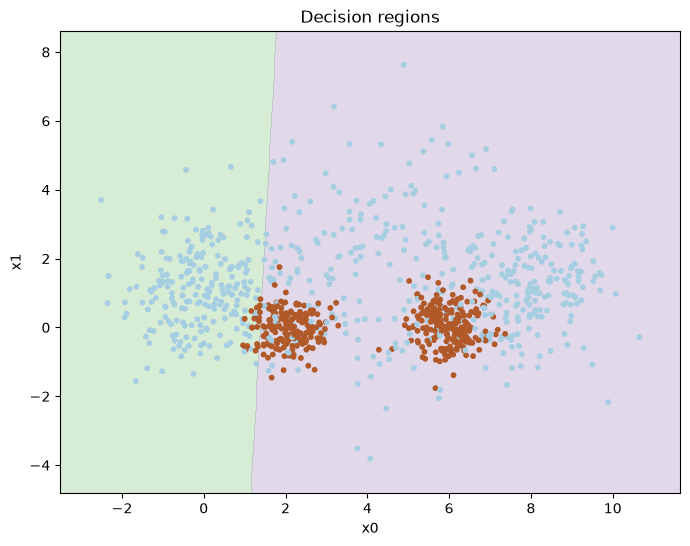

In [127]:
plot_decision_regions(X_train, t2_train, cl)

### Task: Tuning

The result is far from impressive. 
Remember that a classifier which always chooses the majority class will have an accuracy of 0.6 on this data set.

Your task is to try various settings for the two training hyper-parameters, learning rate and the number of epochs, to get the best accuracy on the validation set. 

Report how the accuracy varies with the hyper-parameter settings. It it not sufficient to give the final hyperparameters. You must also show how you found then and results for alternative values you tried aout.

When you are satisfied with the result, you may plot the decision boundaries, as above.

In [ ]:
learning_rates = [0.001, 0.01, 0.05]
epochs_list = [10, 100, 500]

best_accuracy = 0
best_LR = None
best_EPOCHS = None
best_CL = None

for lr in learning_rates:
    for epochs in epochs_list:
        CL = NumpyLinRegClass()
        CL.fit(X_train, t2_train, lr=lr, epochs=epochs)

        val_accuracy = accuracy(CL.predict(X_val), t2_val)
        print(f"Learning rate: {lr}, Epochs: {epochs}, Accuracy: {val_accuracy:.4f}")

        if val_accuracy > best_accuracy:
            best_accuracy = val_accuracy
            best_LR = lr
            best_EPOCHS = epochs
            best_CL = CL

print("Best learning rate:", best_LR)
print("Best epochs:", best_EPOCHS)
print("Best accuracy:", best_accuracy)





Learning rate: 0.001, Epochs: 10, Accuracy: 0.6040
Learning rate: 0.001, Epochs: 100, Accuracy: 0.4880
Learning rate: 0.001, Epochs: 500, Accuracy: 0.5080
Learning rate: 0.01, Epochs: 10, Accuracy: 0.4700
Learning rate: 0.01, Epochs: 100, Accuracy: 0.5660
Learning rate: 0.01, Epochs: 500, Accuracy: 0.6960
Learning rate: 0.05, Epochs: 10, Accuracy: 0.5080
Learning rate: 0.05, Epochs: 100, Accuracy: 0.6960
Learning rate: 0.05, Epochs: 500, Accuracy: 0.7600
Best learning rate: 0.05
Best epochs: 500
Best accuracy: 0.76



##Conclusion

The best learning rate is 0.05
The best epochs is 500
The best accuracy is 0.76



### Task: Scaling

We have seen in Lecture 04 (theory notebook, section 15) that features on different scales make gradient descent harder to tune, and that scaling the data may improve training speed and sometimes the performance. 

- Implement a scaler, at least the standard scaler (normalizer), but you can also try other techniques
- Scale the data
- Train the model on the scaled data
- Experiment with hyper-parameter settings and see whether you can speed  up  the training.
- Report final hyper-parameter settings and show how you found them.

In [ ]:
class StandardScaler:
    """Scales each feature to mean 0 and standard deviation 1"""

    def fit(self, X):
        """Calculate the mean and standard deviation of each feature in X."""
        
        self.mean = np.mean(X,axis = 0)
        self.stddev = np.std(X,axis=0)
        self.stddev = np.where(self.stddev == 0, 1, self.stddev)

        return self

    def transform(self, X):
        """Scale X with the mean and standard deviation learned in fit()."""
        return (X - self.mean) / self.stddev
        

    def normalize(self, X):
        return self.fit(X).transform(X)



scaler = StandardScaler()

X_train_scaled = scaler.normalize(X_train)
X_val_scaled = scaler.transform(X_val)


print("Mean:", np.mean(X_train_scaled, axis=0))
print("Std:", np.std(X_train_scaled, axis=0))
print("Shape:", X_train_scaled.shape)


# Tuning with scaled data
learning_rates = [0.001, 0.01, 0.05]
epochs_list = [10, 100, 500]

best_accuracy_scaled = 0
best_LR_scaled = None
best_EPOCHS_scaled = None
best_CL_scaled = None

for lr in learning_rates:
    for epochs in epochs_list:
        CL = NumpyLinRegClass()
        CL.fit(X_train_scaled, t2_train, lr=lr, epochs=epochs)

        val_accuracy = accuracy(CL.predict(X_val_scaled), t2_val)
        print(f"Learning rate: {lr}, Epochs: {epochs}, Accuracy: {val_accuracy:.4f}")

        if val_accuracy > best_accuracy_scaled:
            best_accuracy_scaled = val_accuracy
            best_LR_scaled = lr
            best_EPOCHS_scaled = epochs
            best_CL_scaled = CL

print("Best learning rate:", best_LR_scaled)
print("Best epochs:", best_EPOCHS_scaled)
print("Best accuracy:", best_accuracy_scaled)





Mean: [ 9.17044218e-17 -1.87072580e-16]
Std: [1. 1.]
Shape: (1000, 2)
Learning rate: 0.001, Epochs: 10, Accuracy: 0.6040
Learning rate: 0.001, Epochs: 100, Accuracy: 0.6040
Learning rate: 0.001, Epochs: 500, Accuracy: 0.6040
Learning rate: 0.01, Epochs: 10, Accuracy: 0.6040
Learning rate: 0.01, Epochs: 100, Accuracy: 0.6000
Learning rate: 0.01, Epochs: 500, Accuracy: 0.7540
Learning rate: 0.05, Epochs: 10, Accuracy: 0.6040
Learning rate: 0.05, Epochs: 100, Accuracy: 0.7540
Learning rate: 0.05, Epochs: 500, Accuracy: 0.7600
Best learning rate: 0.05
Best epochs: 500
Best accuracy: 0.76


##Conclusion

The mean is approximately 0 and the standard deviation is 1.
This shows that the scaling worked correctly.

## Logistic regression
a) You should now implement a logistic regression classifier similarly to the classifier based on linear regression.
You may start from `train_logistic_regression()` in the Lecture 07 notebooks.

b) In addition to the method `predict()` which predicts a class for the data, include a method `predict_probability()` which predict the probability of the data belonging to the positive class.

c) So far, we have not calculated the loss explicitly in the code. Extend the code to calculate the loss on the training set for each epoch and to store the losses such that the losses can be inspected after training. The prefered loss for logistic regression is binary cross-entropy (Lecture 07 practice, Exercise 3), but you can also try mean squared error. The most important is that your implementation of the loss corresponds to your implementation of the gradient descent.
Also, calculate and store accuracies after each epoch.

d) In addition, extend the `fit()` method with optional arguments for a validation set (X_val, t_val). If a validation set is included in the call to `fit()`, calculate the loss and the accuracy for the validation set after each epoch. 

e) The training runs for a number of epochs. We cannot know beforehand for how many epochs it is reasonable to run the training. One possibility is to run the training until the learning does not improve much. Extend the `fit()` method with two keyword arguments, `tol` (tolerance) and `n_epochs_no_update` and stop training when the loss has not improved with more than `tol` after `n_epochs_no_update`. A possible default value for `n_epochs_no_update` is 5. Also, add an attribute to the classifier which tells us after fitting how many epochs it was trained for.

f) Train classifiers with various learning rates, and with varying values for `tol` for finding the optimal values. Also consider the effect of scaling the data.

g) After a succesful training, for your best model, plot both training loss and validation loss as functions of the number of epochs in one figure, and both training and validation accuracies as functions of the number of epochs in another figure. Comment on what you see. Are the curves monotone? Is this as expected?

Validation Accuracy: 0.76
Probabilities: [0.17055791 0.54043214 0.48459407 0.21852645 0.58091734]
First Training Loss: 0.6931471805599454
Final Training Loss: 0.527312910714661
First Training Accuracy: 0.405
Final Training Accuracy: 0.719
Training Loss: 0.5273119856850044
Training Accuracy: 0.719
Validation Loss: 0.49120205462479816
Validation Accuracy: 0.76
Epochs trained: 401
Validation Accuracy: 0.76
Validation Loss: 0.4925771173043021
Original, LR: 0.01, Tolerance: 0.001, Epochs: 251, Accuracy: 0.7340
Original, LR: 0.01, Tolerance: 0.0001, Epochs: 1000, Accuracy: 0.7540
Original, LR: 0.01, Tolerance: 1e-05, Epochs: 1000, Accuracy: 0.7540
Original, LR: 0.05, Tolerance: 0.001, Epochs: 146, Accuracy: 0.7540
Original, LR: 0.05, Tolerance: 0.0001, Epochs: 415, Accuracy: 0.7560
Original, LR: 0.05, Tolerance: 1e-05, Epochs: 913, Accuracy: 0.7600
Original, LR: 0.1, Tolerance: 0.001, Epochs: 104, Accuracy: 0.7560
Original, LR: 0.1, Tolerance: 0.0001, Epochs: 272, Accuracy: 0.7560
Original, 

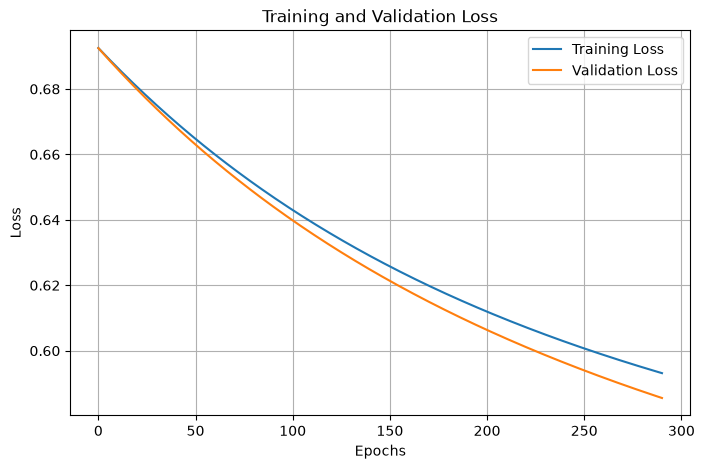

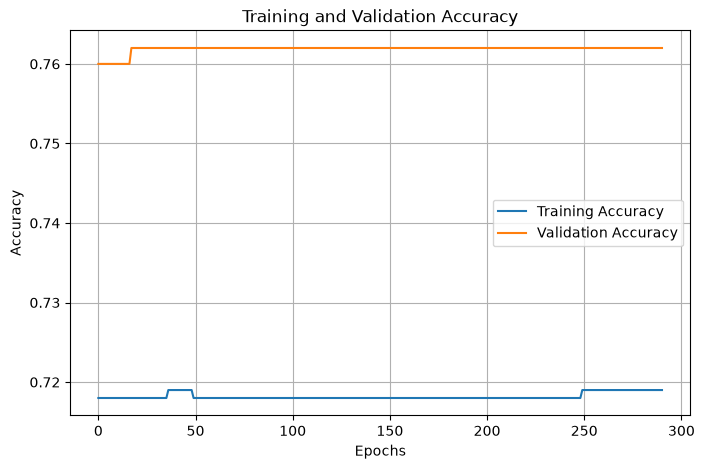

In [ ]:
# Your code here (see Lecture 07 notebooks for help)

#My own code 

#Define the sigmoid and binary cross entropy

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def binary_cross_entropy(y, p):
    eps = 1e-12
    p = np.clip(p, eps, 1 - eps)
    return -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))


#Part a

def train_logistic_regression(X, y, learning_rate=0.1, epochs=500, lambda_=0.0):
    n_samples, n_features = X.shape
    w = np.zeros(n_features)
    b = 0.0
    history = []
    for _ in range(epochs):
        z = X @ w + b
        p = sigmoid(z)
        data_loss = binary_cross_entropy(y, p)
        history.append(data_loss + lambda_ * np.sum(w ** 2))

        error = p - y
        dw = X.T @ error / n_samples
        dw += 2 * lambda_ * w
        db = np.mean(error)


        #Gradient descent
        w -= learning_rate * dw
        b -= learning_rate * db

    return w, b, np.array(history)

class NumpyLogRegClass:
    def __init__(self):
        self.w = None
        self.b = None 
        self.history = None 

    def fit(self, X_train, t_train, learning_rate=0.1, epochs=500, lambda_=0.0):
        self.w, self.b, self.history = train_logistic_regression(X_train, t_train, learning_rate=learning_rate, epochs=epochs, lambda_=lambda_)
        return self 

    def predict(self,X):
        o =  (sigmoid(X @ self.w + self.b) >= 0.5).astype(int)
        return o
#Part b
    def predict_probability(self,X):
        o = sigmoid(X @ self.w + self.b)
        return o

#Test 
CL = NumpyLogRegClass()
CL.fit(X_train_scaled, t2_train, learning_rate=0.1, epochs=500)

print("Validation Accuracy:", accuracy(CL.predict(X_val_scaled), t2_val))
print("Probabilities:", CL.predict_probability(X_val_scaled[:5]))

#Part c
train_loss_history = CL.history
train_accuracy_history = []

w_c = np.zeros(X_train_scaled.shape[1])

b_c = 0.0

for epoch in range(500):
    p_c = sigmoid(X_train_scaled @ w_c + b_c)
    predictions = (p_c >= 0.5).astype(int)
    train_accuracy = np.mean(predictions == t2_train)
    train_accuracy_history.append(train_accuracy)

    error = p_c - t2_train
    dw = X_train_scaled.T @ error / len(t2_train)
    db = np.mean(error)

    #Gradient descent
    w_c -= 0.1 * dw
    b_c -= 0.1 * db

print("First Training Loss:", train_loss_history[0])
print("Final Training Loss:", train_loss_history[-1])
print("First Training Accuracy:", train_accuracy_history[0])
print("Final Training Accuracy:", train_accuracy_history[-1])
#Part d

class NumpyLogRegClassExtended(NumpyLogRegClass):
    def __init__(self):
        super().__init__()
        self.accuracy_history = []
        self.val_loss_history = []
        self.val_accuracy_history = []
        self.n_epochs_trained = 0

    def fit(self, X_train, t_train, learning_rate=0.1, epochs=500, lambda_=0.0, X_val=None, t_val=None, tol=None, n_epochs_no_update=5):
        if (X_val is None) != (t_val is None):
            raise ValueError("X_val and t_val must both be provided")

        n_samples, n_features = X_train.shape
        self.w = np.zeros(n_features)
        self.b = 0.0
        self.history = []
        self.accuracy_history = []
        self.val_loss_history = []
        self.val_accuracy_history = []
        self.n_epochs_trained = 0
        best_loss = float("inf")
        no_update = 0

        for epoch in range(epochs):
            p = sigmoid(X_train @ self.w + self.b)
            error = p - t_train
            dw = X_train.T @ error / n_samples + 2 * lambda_ * self.w
            db = np.mean(error)

            #Gradient descent
            self.w -= learning_rate * dw
            self.b -= learning_rate * db

            #Training loss and accuracy
            p_train = sigmoid(X_train @ self.w + self.b)
            train_loss = binary_cross_entropy(t_train, p_train) + lambda_ * np.sum(self.w ** 2)
            self.history.append(train_loss)
            self.accuracy_history.append(np.mean((p_train >= 0.5) == t_train))

            #Validation loss and accuracy
            if X_val is not None:
                p_val = sigmoid(X_val @ self.w + self.b)
                val_loss = binary_cross_entropy(t_val, p_val)
                self.val_loss_history.append(val_loss)
                self.val_accuracy_history.append(np.mean((p_val >= 0.5) == t_val))

            #Part e - Early stopping
            self.n_epochs_trained = epoch + 1
            monitored_loss = val_loss if X_val is not None else train_loss

            if tol is not None:
                if best_loss - monitored_loss > tol:
                    best_loss = monitored_loss
                    no_update = 0
                else:
                    no_update += 1

                if no_update >= n_epochs_no_update:
                    break

        self.history = np.array(self.history)
        self.accuracy_history = np.array(self.accuracy_history)
        self.val_loss_history = np.array(self.val_loss_history)
        self.val_accuracy_history = np.array(self.val_accuracy_history)

        return self


#Test Part d
CL_d = NumpyLogRegClassExtended()
CL_d.fit(X_train_scaled, t2_train, X_val=X_val_scaled, t_val=t2_val, learning_rate=0.1, epochs=500)

print("Training Loss:", CL_d.history[-1])
print("Training Accuracy:", CL_d.accuracy_history[-1])
print("Validation Loss:", CL_d.val_loss_history[-1])
print("Validation Accuracy:", CL_d.val_accuracy_history[-1])
#Part e

CL_e = NumpyLogRegClassExtended()
CL_e.fit(X_train_scaled, t2_train, X_val=X_val_scaled, t_val=t2_val, learning_rate=0.1, epochs=1000, tol=0.0001, n_epochs_no_update=5)

print("Epochs trained:", CL_e.n_epochs_trained)
print("Validation Accuracy:", CL_e.val_accuracy_history[-1])
print("Validation Loss:", CL_e.val_loss_history[-1])

#Part f

learning_rates = [0.01, 0.05, 0.1]
tolerances = [0.001, 0.0001, 0.00001]

best_log_accuracy = -1
best_log_model = None
best_log_config = None

datasets = [("Original", X_train, X_val), ("Scaled", X_train_scaled, X_val_scaled)]

for label, X_tr, X_v in datasets:
    for lr in learning_rates:
        for tol in tolerances:
            CL = NumpyLogRegClassExtended()
            CL.fit(X_tr, t2_train, X_val=X_v, t_val=t2_val, learning_rate=lr, epochs=1000, tol=tol, n_epochs_no_update=5)

            val_accuracy = CL.val_accuracy_history[-1]
            print(f"{label}, LR: {lr}, Tolerance: {tol}, Epochs: {CL.n_epochs_trained}, Accuracy: {val_accuracy:.4f}")

            if val_accuracy > best_log_accuracy:
                best_log_accuracy = val_accuracy
                best_log_model = CL
                best_log_config = (label, lr, tol)

print("Best configuration:", best_log_config)
print("Best accuracy:", best_log_accuracy)
print("Best epochs:", best_log_model.n_epochs_trained)

#Part g

#Training and Validation Loss
plt.figure(figsize=(8,5))
plt.plot(best_log_model.history, label="Training Loss")
plt.plot(best_log_model.val_loss_history, label="Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.show()


#Training and Validation Accuracy
plt.figure(figsize=(8,5))
plt.plot(best_log_model.accuracy_history, label="Training Accuracy")
plt.plot(best_log_model.val_accuracy_history, label="Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()
plt.grid(True)
plt.show()



#Conclusion


The best validation accuracy is 76.2% using scaled data.

The training and validation losses decrease smoothly.

The accuracy stays almost constant despite decreasing loss.

No clear overfitting is observed.

Early stopping reduces unnecessary training.

LR=0.1 and tol=0.001 achieve 76.2% accuracy in only 148 epochs.

## Multi-class classifiers
We turn to the task of classifying when there are more than two classes, and the task is to ascribe one class to each input. We will now use the set (X, t_multi).

### "One-vs-rest" with logistic regression
We saw in Lecture 07 (theory notebook, section 10) how a logistic regression classifier can be turned into a multi-class classifier using the one-vs-rest approach. We train one logistic regression classifier for each class. To predict the class of an item, we run all the binary classifiers and collect the probability score from each of them. We assign the class which ascribes the highest probability.

Build such a classifier. Train the resulting classifier on (X_train, t_multi_train), test it on (X_val, t_multi_val), tune the hyper-parameters and report the accuracy.

Also plot the decision boundaries for your best classifier similarly to the plots for the binary case.

Validation Accuracy: 0.83
First 5 predictions: [0 4 3 2 3]
First 5 true labels: [0 4 3 2 3]
Learning rate: 0.01, Epochs: 100, Accuracy: 0.7420
Learning rate: 0.01, Epochs: 300, Accuracy: 0.7460
Learning rate: 0.01, Epochs: 500, Accuracy: 0.7560
Learning rate: 0.05, Epochs: 100, Accuracy: 0.7560
Learning rate: 0.05, Epochs: 300, Accuracy: 0.7860
Learning rate: 0.05, Epochs: 500, Accuracy: 0.8180
Learning rate: 0.1, Epochs: 100, Accuracy: 0.7800
Learning rate: 0.1, Epochs: 300, Accuracy: 0.8280
Learning rate: 0.1, Epochs: 500, Accuracy: 0.8300
Best Learning Rate: 0.1
Best Epochs: 500
Best Accuracy: 0.83


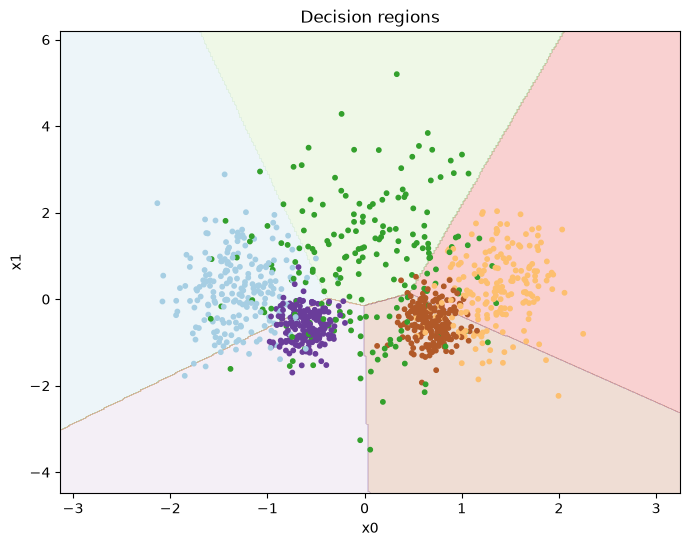

In [ ]:
# Your code here (see Lecture 07 theory notebook, section 10, and practice Exercises 1-6 for the binary classifiers)

#Multi-class classifiers

#One-vs-rest with Logistic Regression

class OneVsRest:
    def __init__(self):
        self.models = []
        self.classes = None

    def fit(self, X_train, t_train, learning_rate=0.1, epochs=500):
        self.classes = np.unique(t_train)
        self.models = []

        for class_label in self.classes:
            t_binary = (t_train == class_label).astype(int)

            model = NumpyLogRegClass()
            model.fit(X_train, t_binary, learning_rate=learning_rate, epochs=epochs)
            self.models.append(model)

        return self

    def predict_probability(self, X):
        probabilities = np.column_stack([model.predict_probability(X) for model in self.models])
        return probabilities

    def predict(self, X):
        probabilities = self.predict_probability(X)
        predictions = np.argmax(probabilities, axis=1)
        return self.classes[predictions]

#Training and Validation

CL_multi = OneVsRest()
CL_multi.fit(X_train_scaled, t_multi_train, learning_rate=0.1, epochs=500)

predictions = CL_multi.predict(X_val_scaled)
val_accuracy = accuracy(predictions, t_multi_val)

print("Validation Accuracy:", val_accuracy)
print("First 5 predictions:", predictions[:5])
print("First 5 true labels:", t_multi_val[:5])


#Hyperparameter Tuning

learning_rates = [0.01, 0.05, 0.1]
epochs_list = [100, 300, 500]

best_accuracy = 0
best_LR = None
best_EPOCHS = None
best_CL = None

for lr in learning_rates:
    for epochs in epochs_list:
        CL = OneVsRest()
        CL.fit(X_train_scaled, t_multi_train, learning_rate=lr, epochs=epochs)

        val_accuracy = accuracy(CL.predict(X_val_scaled), t_multi_val)
        print(f"Learning rate: {lr}, Epochs: {epochs}, Accuracy: {val_accuracy:.4f}")

        if val_accuracy > best_accuracy:
            best_accuracy = val_accuracy
            best_LR = lr
            best_EPOCHS = epochs
            best_CL = CL

print("Best Learning Rate:", best_LR)
print("Best Epochs:", best_EPOCHS)
print("Best Accuracy:", best_accuracy)


#Decision Boundaries

plot_decision_regions(X_train_scaled, t_multi_train, best_CL)
plt.show()



#Conclusion

The Validation accuracy is 0.83

The best learning rate is 0.1

The best number of epochs is 500

The best accuracy is 83%

Higher learning rates and more epochs generally improve the accuracy

The decision boundaries separate the five classes well, but some points are misclassified 

### Multinomial logistic regression
In Lecture 07 (theory notebook, sections 11 and 12), we contrasted the one-vs-rest approach with the multinomial logistic regression, also called softmax classifier. Implement also this classifier, tune the parameters, and compare the results to the one-vs-rest classifier. (Don't expect a large difference on a simple task like this.)

Remember that this classifier uses softmax in the forward phase. For loss, it uses categorical cross-entropy loss. The loss has a somewhat simpler form than in the binary case. To calculate the gradient is a little more complicated. The actual gradient and update rule is simple, however, as long as you have calculated the forward values correctly (see section 12 of the Lecture 07 theory notebook).

The functions `softmax()` and `multiclass_cross_entropy()` below are from the Lecture 07 solutions and correspond to practice Exercises 7 and 8. Note that `multiclass_cross_entropy()` sums over all data points, while `binary_cross_entropy()` takes the mean.

Validation Accuracy: 0.848
First 5 predictions: [0 4 3 2 3]
First 5 probabilities: [[0.54866974 0.27590503 0.00284671 0.15848777 0.01409075]
 [0.00723356 0.14415057 0.2480979  0.09562932 0.50488865]
 [0.32831797 0.14580826 0.00445669 0.46467996 0.05673712]
 [0.00188341 0.19614165 0.57332239 0.01239364 0.2162589 ]
 [0.21979255 0.12822392 0.00704026 0.54745248 0.0974908 ]]
Learning rate: 0.01, Epochs: 100, Accuracy: 0.7420
Learning rate: 0.01, Epochs: 300, Accuracy: 0.7600
Learning rate: 0.01, Epochs: 500, Accuracy: 0.7800
Learning rate: 0.05, Epochs: 100, Accuracy: 0.7800
Learning rate: 0.05, Epochs: 300, Accuracy: 0.8140
Learning rate: 0.05, Epochs: 500, Accuracy: 0.8160
Learning rate: 0.1, Epochs: 100, Accuracy: 0.8040
Learning rate: 0.1, Epochs: 300, Accuracy: 0.8200
Learning rate: 0.1, Epochs: 500, Accuracy: 0.8480
Best Learning Rate: 0.1
Best Epochs: 500
Best Accuracy: 0.848
One-vs-Rest Accuracy: 0.83
Softmax Accuracy: 0.848
Difference: 0.018000000000000016


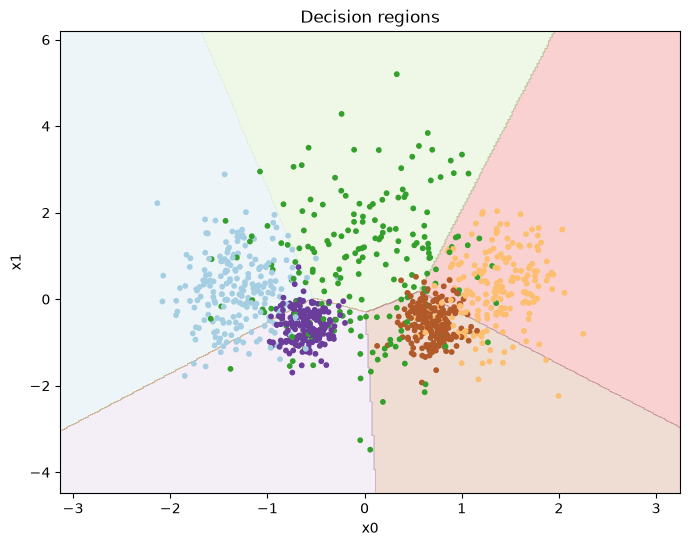

In [ ]:
def softmax(z, axis=-1):
    shifted = z - np.max(z, axis=axis, keepdims=True)
    exp_z = np.exp(shifted)
    return exp_z / exp_z.sum(axis=axis, keepdims=True)


def multiclass_cross_entropy(target, probabilities):
    probabilities = np.clip(probabilities, 1e-12, 1 - 1e-12)
    return -np.sum(target * np.log(probabilities))

#Multinomial Logistic Regression

#My own code

class NumpySoftmaxClass:
    def __init__(self):
        self.W = None
        self.b = None
        self.history = []
        self.classes = None

    def fit(self, X_train, t_train, learning_rate=0.1, epochs=500):
        n_samples, n_features = X_train.shape
        self.classes = np.unique(t_train)
        n_classes = len(self.classes)

        self.W = np.zeros((n_features, n_classes))
        self.b = np.zeros(n_classes)
        self.history = []

        Y = (t_train[:, None] == self.classes).astype(int)

        for epoch in range(epochs):
            z = X_train @ self.W + self.b
            p = softmax(z)

            error = p - Y
            dw = X_train.T @ error / n_samples
            db = np.mean(error, axis=0)

            #Gradient descent
            self.W -= learning_rate * dw
            self.b -= learning_rate * db

            #Training Loss
            p_new = softmax(X_train @ self.W + self.b)
            loss = multiclass_cross_entropy(Y, p_new) / n_samples
            self.history.append(loss)

        return self

    def predict_probability(self, X):
        return softmax(X @ self.W + self.b)

    def predict(self, X):
        probabilities = self.predict_probability(X)
        predictions = np.argmax(probabilities, axis=1)
        return self.classes[predictions]

#Test

CL_softmax = NumpySoftmaxClass()
CL_softmax.fit(X_train_scaled, t_multi_train, learning_rate=0.1, epochs=500)

print("Validation Accuracy:", accuracy(CL_softmax.predict(X_val_scaled), t_multi_val))
print("First 5 predictions:", CL_softmax.predict(X_val_scaled[:5]))
print("First 5 probabilities:", CL_softmax.predict_probability(X_val_scaled[:5]))

#Hyperparameter Tuning

learning_rates = [0.01, 0.05, 0.1]
epochs_list = [100, 300, 500]

best_accuracy_softmax = 0
best_LR_softmax = None
best_EPOCHS_softmax = None
best_CL_softmax = None

for lr in learning_rates:
    for epochs in epochs_list:
        CL = NumpySoftmaxClass()
        CL.fit(X_train_scaled, t_multi_train, learning_rate=lr, epochs=epochs)

        val_accuracy = accuracy(CL.predict(X_val_scaled), t_multi_val)
        print(f"Learning rate: {lr}, Epochs: {epochs}, Accuracy: {val_accuracy:.4f}")

        if val_accuracy > best_accuracy_softmax:
            best_accuracy_softmax = val_accuracy
            best_LR_softmax = lr
            best_EPOCHS_softmax = epochs
            best_CL_softmax = CL

print("Best Learning Rate:", best_LR_softmax)
print("Best Epochs:", best_EPOCHS_softmax)
print("Best Accuracy:", best_accuracy_softmax)


#Comparison

print("One-vs-Rest Accuracy:", 0.83)
print("Softmax Accuracy:", best_accuracy_softmax)
print("Difference:", best_accuracy_softmax - 0.83)


#Decision Boundaries

plot_decision_regions(X_train_scaled, t_multi_train, best_CL_softmax)
plt.show()




#Conclusion


The validation accuracy is 0.848


The best learning rate is 0.1


The best number of epochs is 500

The best accuracy is 84.8%


One-vs-Rest accuracy is 83%

Softmax accuracy is 84.8%

The difference is 1.8 percentage points

Softmax performs slightly better than One-vs-Rest

The decision boundaries separate the five classes reasonably well

# Part 2: Multi-layer neural networks

## A first non-linear classifier

The following code is a simple implementation of a multi-layer perceptron or feed-forward neural network.
For now, it is quite restricted.
There is only one hidden layer.
It can only handle binary classification.
In addition, it uses a simple final layer similar to the linear regression classifier above.
One way to look at it is what happens when we add a hidden layer to the linear regression classifier.

For inspiration and further help, see the Lecture 08 notebooks (`Lecture_08_Backpropagation`).

The MLP class below misses the implementation of the `forward()` function. Your first task is to implement it. 

Remember that in the forward pass, we "feed" the input to the model, the model processes it and produces the output. The function should make use of the logistic activation function and bias. Lecture 08 practice, Exercise 1, shows the forward pass for a single data point, with the biases as separate vectors.

In [133]:
# First, we define the logistic function and its derivative:
def logistic(x):
    return 1/(1+np.exp(-x))

def logistic_diff(y):
    return y * (1 - y)

Training Accuracy: 0.746
Validation Accuracy: 0.794


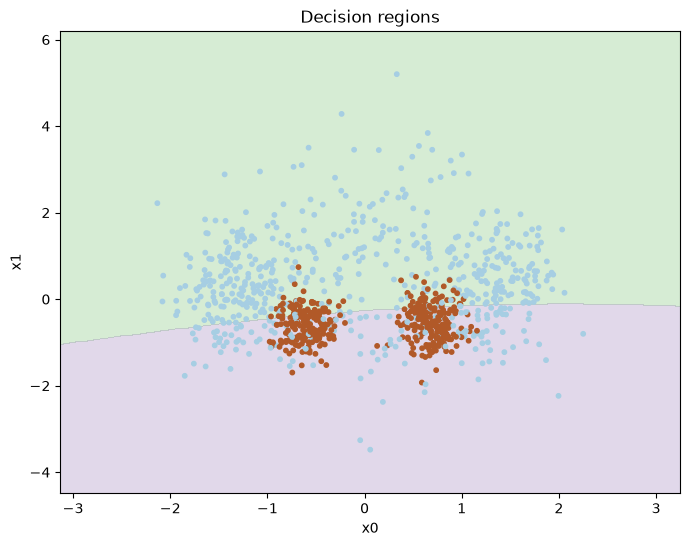

Learning rate: 5e-05, Epochs: 500, Accuracy: 0.7740
Learning rate: 5e-05, Epochs: 1000, Accuracy: 0.7940
Learning rate: 5e-05, Epochs: 2000, Accuracy: 0.7900
Learning rate: 0.0001, Epochs: 500, Accuracy: 0.7940
Learning rate: 0.0001, Epochs: 1000, Accuracy: 0.7900
Learning rate: 0.0001, Epochs: 2000, Accuracy: 0.7900
Learning rate: 0.0002, Epochs: 500, Accuracy: 0.7900
Learning rate: 0.0002, Epochs: 1000, Accuracy: 0.7900
Learning rate: 0.0002, Epochs: 2000, Accuracy: 0.8000
Best Learning Rate: 0.0002
Best Epochs: 2000
Best Accuracy: 0.8
Best Training Accuracy: 0.789
Best Validation Accuracy: 0.8


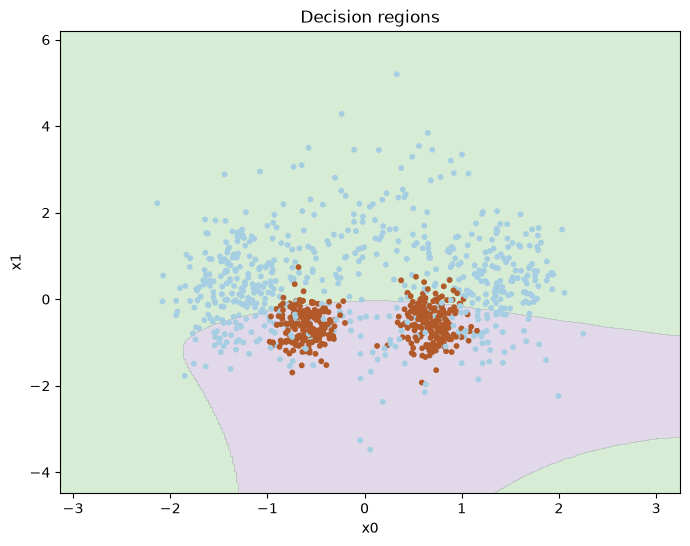

In [ ]:
class MLPBinaryLinRegClass(NumpyClassifier):
    """A multi-layer neural network with one hidden layer"""
    
    def __init__(self, bias=-1, dim_hidden = 6):
        """Intialize the hyperparameters"""
        self.bias = bias
        # Dimensionality of the hidden layer
        self.dim_hidden = dim_hidden
        
        self.activ = logistic
        
        self.activ_diff = logistic_diff
        
    def forward(self, X):
        """TODO: 
        Perform one forward step. 
        Return a pair consisting of the outputs of the hidden_layer
        and the outputs on the final layer"""
        
        hidden = self.activ(X @ self.weights1)
        hidden_outs = add_bias(hidden, self.bias)
        outputs = hidden_outs @ self.weights2

        return hidden_outs, outputs
    
    def fit(self, X_train, t_train, lr=0.001, epochs = 100):
        """Initialize the weights. Train *epochs* many epochs.
        
        X_train is a NxM matrix, N data points, M features
        t_train is a vector of length N of targets values for the training data, 
        where the values are 0 or 1.
        lr is the learning rate
        """
        self.lr = lr
        
        # Turn t_train into a column vector, a N*1 matrix:
        T_train = t_train.reshape(-1,1)
            
        dim_in = X_train.shape[1] 
        dim_out = T_train.shape[1]
        
        # Initialize the weights
        self.weights1 = (np.random.rand(
            dim_in + 1, 
            self.dim_hidden) * 2 - 1)/np.sqrt(dim_in)
        self.weights2 = (np.random.rand(
            self.dim_hidden+1, 
            dim_out) * 2 - 1)/np.sqrt(self.dim_hidden)
        X_train_bias = add_bias(X_train, self.bias)
        
        for e in range(epochs):
            # One epoch
            # The forward step:
            hidden_outs, outputs = self.forward(X_train_bias)
            # The delta term on the output node:
            out_deltas = (outputs - T_train)
            # The delta terms at the output of the hidden layer:
            hiddenout_diffs = out_deltas @ self.weights2.T
            # The deltas at the input to the hidden layer:
            hiddenact_deltas = (hiddenout_diffs[:, 1:] * 
                                self.activ_diff(hidden_outs[:, 1:]))  

            # Update the weights:
            self.weights2 -= self.lr * hidden_outs.T @ out_deltas
            self.weights1 -= self.lr * X_train_bias.T @ hiddenact_deltas 
            
    
    def predict(self, X):
        """Predict the class for the members of X"""
        Z = add_bias(X, self.bias)
        forw = self.forward(Z)[1]
        score= forw[:, 0]
        return (score > 0.5)

#Training MLP

MLP = MLPBinaryLinRegClass(bias=-1, dim_hidden=6)
MLP.fit(X_train_scaled, t2_train, lr=0.0001, epochs=1000)

print("Training Accuracy:", accuracy(MLP.predict(X_train_scaled), t2_train))
print("Validation Accuracy:", accuracy(MLP.predict(X_val_scaled), t2_val))


#Decision Boundaries

plot_decision_regions(X_train_scaled, t2_train, MLP)
plt.show()


#Hyperparameter Tuning

learning_rates = [0.00005, 0.0001, 0.0002]
epochs_list = [500, 1000, 2000]

best_accuracy = 0
best_LR = None
best_EPOCHS = None
best_MLP = None

for lr in learning_rates:
    for epochs in epochs_list:
        np.random.seed(2024)
        MLP = MLPBinaryLinRegClass(bias=-1, dim_hidden=6)
        MLP.fit(X_train_scaled, t2_train, lr=lr, epochs=epochs)

        val_accuracy = accuracy(MLP.predict(X_val_scaled), t2_val)
        print(f"Learning rate: {lr}, Epochs: {epochs}, Accuracy: {val_accuracy:.4f}")

        if val_accuracy > best_accuracy:
            best_accuracy = val_accuracy
            best_LR = lr
            best_EPOCHS = epochs
            best_MLP = MLP

print("Best Learning Rate:", best_LR)
print("Best Epochs:", best_EPOCHS)
print("Best Accuracy:", best_accuracy)


print("Best Training Accuracy:", accuracy(best_MLP.predict(X_train_scaled), t2_train))
print("Best Validation Accuracy:", accuracy(best_MLP.predict(X_val_scaled), t2_val))

plot_decision_regions(X_train_scaled, t2_train, best_MLP)
plt.show()

When implemented, this model can be used to make a non-linear classifier for the set `(X, t2)`. Experiment with settings for learning rate and epochs and see how good results you can get. 
Report results for various settings. Be prepared to train for a long time (but you can control it via the number of epochs and hidden size). 

Plot the training set together with the decision regions as in Part I.

#Conclusion


The training accuracy is 0.746

The validation accuracy is 0.794

The MLP performs better than the previous binary logistic regression model

The decision boundary is still approximately linear





Best Learning Rate: 0.0002

Best Epochs: 2000

Best Accuracy: 0.8

Best Training Accuracy: 0.789

Best Validation Accuracy: 0.8


The MLP performs better than the previous binary logistic regression model

The validation accuracy improved from 0.762 to 0.8

More epochs generally improved the accuracy in the tested settings

# Improving the MLP classifier
You should now make changes to the classifier similarly to what you did with the logistic regression classifier in part 1.

a) In addition to the `predict()` method, which predicts a class for the data, include the `predict_probability()` method which predict the probability of the data belonging to the positive class. The training should be based on these values, as with logistic regression. The Lecture 08 network has such an output layer.

b) Calculate the loss and the accuracy after each epoch and store them for inspection after training.

c) Extend the `fit()` method with optional arguments for a validation set `(X_val, t_val)`. If a validation set is included in the call to `fit()`, calculate the loss and the accuracy for the validation set after each epoch.

d) Extend the `fit()` method with two keyword arguments, `tol` (tolerance) and `n_epochs_no_update` and stop training when the loss has not improved for more than `tol` after `n_epochs_no_update`. A possible default value for `n_epochs_no_update` is 5. Add an attribute to the classifier which tells us after fitting how many epochs it was trained on.

e) Tune the hyper-parameters: `lr`, `tol` and `dim-hidden` (size of the hidden layer).
Also, consider the effect of scaling the data.

f) After a succesful training with the best setting for the hyper-parameters, plot both training loss and validation loss as functions of the number of epochs in one figure, and both training and validation accuracies as functions of the number of epochs in another figure. Comment on what you see.

g) The MLP algorithm contains an element of non-determinism. Hence, train the classifier 10 times with the optimal hyper-parameters and report the mean and standard deviation of the accuracies over the 10 runs.

# Your code here



Probabilities: [0.21454808 0.53221128 0.48509079 0.2597336  0.55069686]
Predictions: [0 1 0 0 1]
Validation Accuracy: 0.762
Training Loss: 0.5217765842566289
Training Accuracy: 0.72
Validation Loss: 0.5065818081109563
Validation Accuracy: 0.762
Number of Epochs: 500
Epochs trained: 1000
Training Loss: 0.48883470907904975
Training Accuracy: 0.737
Validation Loss: 0.4670857848070034
Validation Accuracy: 0.788
Data: Original, LR: 0.05, Tol: 0.001, Hidden: 6, Epochs: 575, Accuracy: 0.7440
Data: Original, LR: 0.05, Tol: 0.001, Hidden: 12, Epochs: 43, Accuracy: 0.6040
Data: Original, LR: 0.05, Tol: 0.0001, Hidden: 6, Epochs: 1000, Accuracy: 0.8060
Data: Original, LR: 0.05, Tol: 0.0001, Hidden: 12, Epochs: 1000, Accuracy: 0.7720
Data: Original, LR: 0.1, Tol: 0.001, Hidden: 6, Epochs: 497, Accuracy: 0.8060
Data: Original, LR: 0.1, Tol: 0.001, Hidden: 12, Epochs: 504, Accuracy: 0.7760
Data: Original, LR: 0.1, Tol: 0.0001, Hidden: 6, Epochs: 1000, Accuracy: 0.8300
Data: Original, LR: 0.1, Tol: 0

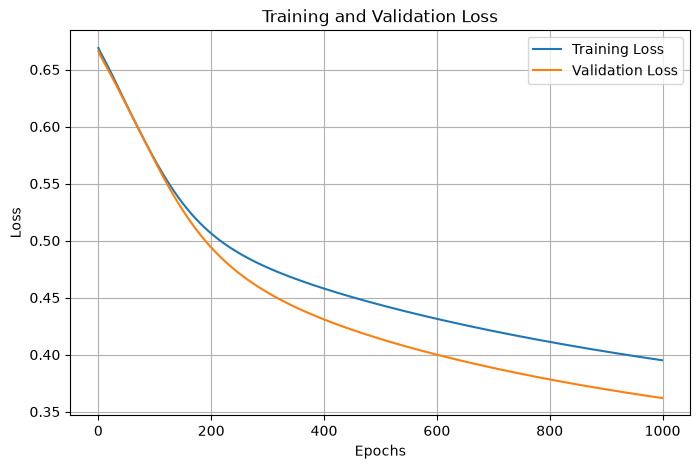

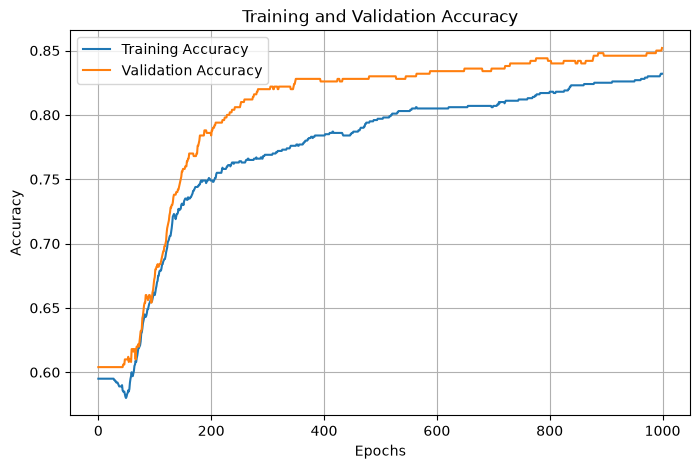

Run 1, Accuracy: 0.8520
Run 2, Accuracy: 0.8440
Run 3, Accuracy: 0.8420
Run 4, Accuracy: 0.8540
Run 5, Accuracy: 0.8420
Run 6, Accuracy: 0.8480
Run 7, Accuracy: 0.8400
Run 8, Accuracy: 0.8340
Run 9, Accuracy: 0.8500
Run 10, Accuracy: 0.8400
Mean Accuracy: 0.8446
Standard Deviation: 0.005936328831862337


In [ ]:
#My own code 

#My own code

#Part a

class ImprovedMLPBinaryClass(MLPBinaryLinRegClass):
    def __init__(self, bias=-1, dim_hidden=6):
        super().__init__(bias=bias, dim_hidden=dim_hidden)

    def forward(self, X):
        hidden = self.activ(X @ self.weights1)
        hidden_outs = add_bias(hidden, self.bias)
        outputs = logistic(hidden_outs @ self.weights2)
        return hidden_outs, outputs

    def fit(self, X_train, t_train, lr=0.1, epochs=500):
        N, D = X_train.shape
        T = t_train.reshape(-1, 1)

        #Initialize the weights
        self.weights1 = (np.random.rand(D + 1, self.dim_hidden) * 2 - 1) / np.sqrt(D)
        self.weights2 = (np.random.rand(self.dim_hidden + 1, 1) * 2 - 1) / np.sqrt(self.dim_hidden)
        X_train_bias = add_bias(X_train, self.bias)

        for epoch in range(epochs):
            #Forward
            hidden_outs, outputs = self.forward(X_train_bias)

            #Backpropagation
            out_deltas = outputs - T
            hiddenact_deltas = (out_deltas @ self.weights2[1:, :].T) * self.activ_diff(hidden_outs[:, 1:])

            #Gradient descent
            self.weights2 -= lr * hidden_outs.T @ out_deltas / N
            self.weights1 -= lr * X_train_bias.T @ hiddenact_deltas / N

        return self

    def predict_probability(self, X):
        outputs = self.forward(add_bias(X, self.bias))[1]
        return outputs[:, 0]

    def predict(self, X):
        return (self.predict_probability(X) >= 0.5).astype(int)


#Test Part a

np.random.seed(2024)

MLP_new = ImprovedMLPBinaryClass(bias=-1, dim_hidden=6)
MLP_new.fit(X_train_scaled, t2_train, lr=0.1, epochs=500)

print("Probabilities:", MLP_new.predict_probability(X_val_scaled[:5]))
print("Predictions:", MLP_new.predict(X_val_scaled[:5]))
print("Validation Accuracy:", accuracy(MLP_new.predict(X_val_scaled), t2_val))


#Part b

class ImprovedMLPBinaryClassB(ImprovedMLPBinaryClass):
    def fit(self, X_train, t_train, lr=0.1, epochs=500):
        N, D = X_train.shape
        T = t_train.reshape(-1, 1)

        #Initialize the weights
        self.weights1 = (np.random.rand(D + 1, self.dim_hidden) * 2 - 1) / np.sqrt(D)
        self.weights2 = (np.random.rand(self.dim_hidden + 1, 1) * 2 - 1) / np.sqrt(self.dim_hidden)
        X_train_bias = add_bias(X_train, self.bias)

        self.history = []
        self.accuracy_history = []

        for epoch in range(epochs):
            #Forward
            hidden_outs, outputs = self.forward(X_train_bias)

            #Backpropagation
            out_deltas = outputs - T
            hiddenact_deltas = (out_deltas @ self.weights2[1:, :].T) * self.activ_diff(hidden_outs[:, 1:])

            #Gradient descent
            self.weights2 -= lr * hidden_outs.T @ out_deltas / N
            self.weights1 -= lr * X_train_bias.T @ hiddenact_deltas / N

            #Training Loss and Accuracy
            p_train = self.predict_probability(X_train)
            train_loss = binary_cross_entropy(t_train, p_train)
            train_accuracy = np.mean((p_train >= 0.5) == t_train)

            self.history.append(train_loss)
            self.accuracy_history.append(train_accuracy)

        return self

#Part c

class ImprovedMLPBinaryClassC(ImprovedMLPBinaryClassB):
    def fit(self, X_train, t_train, lr=0.1, epochs=500, X_val=None, t_val=None):
        if (X_val is None) != (t_val is None):
            raise ValueError("Provide both X_val and t_val")

        N, D = X_train.shape
        T = t_train.reshape(-1, 1)

        #Initialize the weights
        self.weights1 = (np.random.rand(D + 1, self.dim_hidden) * 2 - 1) / np.sqrt(D)
        self.weights2 = (np.random.rand(self.dim_hidden + 1, 1) * 2 - 1) / np.sqrt(self.dim_hidden)
        X_train_bias = add_bias(X_train, self.bias)

        self.history = []
        self.accuracy_history = []
        self.val_loss_history = []
        self.val_accuracy_history = []

        for epoch in range(epochs):
            #Forward
            hidden_outs, outputs = self.forward(X_train_bias)

            #Backpropagation
            out_deltas = outputs - T
            hiddenact_deltas = (out_deltas @ self.weights2[1:, :].T) * self.activ_diff(hidden_outs[:, 1:])

            #Gradient descent
            self.weights2 -= lr * hidden_outs.T @ out_deltas / N
            self.weights1 -= lr * X_train_bias.T @ hiddenact_deltas / N

            #Training Loss and Accuracy
            p_train = self.predict_probability(X_train)
            train_loss = binary_cross_entropy(t_train, p_train)
            train_accuracy = np.mean((p_train >= 0.5) == t_train)

            self.history.append(train_loss)
            self.accuracy_history.append(train_accuracy)

            #Validation Loss and Accuracy
            if X_val is not None:
                p_val = self.predict_probability(X_val)
                val_loss = binary_cross_entropy(t_val, p_val)
                val_accuracy = np.mean((p_val >= 0.5) == t_val)

                self.val_loss_history.append(val_loss)
                self.val_accuracy_history.append(val_accuracy)

        return self

#Test Part c

np.random.seed(2024)

MLP_c = ImprovedMLPBinaryClassC(bias=-1, dim_hidden=6)
MLP_c.fit(X_train_scaled, t2_train, lr=0.1, epochs=500, X_val=X_val_scaled, t_val=t2_val)

print("Training Loss:", MLP_c.history[-1])
print("Training Accuracy:", MLP_c.accuracy_history[-1])

print("Validation Loss:", MLP_c.val_loss_history[-1])
print("Validation Accuracy:", MLP_c.val_accuracy_history[-1])

print("Number of Epochs:", len(MLP_c.val_loss_history))

#Part d

class ImprovedMLPBinaryClassD(ImprovedMLPBinaryClassC):
    def fit(self, X_train, t_train, lr=0.1, epochs=500, X_val=None, t_val=None, tol=0.0001, n_epochs_no_update=5):
        if (X_val is None) != (t_val is None):
            raise ValueError("Provide both X_val and t_val")

        N, D = X_train.shape
        T = t_train.reshape(-1, 1)

        #Initialize the weights
        self.weights1 = (np.random.rand(D + 1, self.dim_hidden) * 2 - 1) / np.sqrt(D)
        self.weights2 = (np.random.rand(self.dim_hidden + 1, 1) * 2 - 1) / np.sqrt(self.dim_hidden)
        X_train_bias = add_bias(X_train, self.bias)

        self.history = []
        self.accuracy_history = []
        self.val_loss_history = []
        self.val_accuracy_history = []

        #Early Stopping
        best_loss = float("inf")
        no_update = 0
        self.n_epochs_trained = 0

        for epoch in range(epochs):
            #Forward
            hidden_outs, outputs = self.forward(X_train_bias)

            #Backpropagation
            out_deltas = outputs - T
            hiddenact_deltas = (out_deltas @ self.weights2[1:, :].T) * self.activ_diff(hidden_outs[:, 1:])

            #Gradient descent
            self.weights2 -= lr * hidden_outs.T @ out_deltas / N
            self.weights1 -= lr * X_train_bias.T @ hiddenact_deltas / N

            #Training Loss and Accuracy
            p_train = self.predict_probability(X_train)
            train_loss = binary_cross_entropy(t_train, p_train)
            train_accuracy = np.mean((p_train >= 0.5) == t_train)

            self.history.append(train_loss)
            self.accuracy_history.append(train_accuracy)

            #Validation Loss and Accuracy
            if X_val is not None:
                p_val = self.predict_probability(X_val)
                val_loss = binary_cross_entropy(t_val, p_val)
                val_accuracy = np.mean((p_val >= 0.5) == t_val)

                self.val_loss_history.append(val_loss)
                self.val_accuracy_history.append(val_accuracy)

            #Early Stopping
            self.n_epochs_trained = epoch + 1
            monitored_loss = val_loss if X_val is not None else train_loss

            if tol is not None:
                if best_loss - monitored_loss > tol:
                    best_loss = monitored_loss
                    no_update = 0
                else:
                    no_update += 1

                if no_update >= n_epochs_no_update:
                    break

        return self

#Test Part d

np.random.seed(2024)

MLP_d = ImprovedMLPBinaryClassD(bias=-1, dim_hidden=6)
MLP_d.fit(X_train_scaled, t2_train, lr=0.1, epochs=1000, X_val=X_val_scaled, t_val=t2_val, tol=0.0001, n_epochs_no_update=5)

print("Epochs trained:", MLP_d.n_epochs_trained)
print("Training Loss:", MLP_d.history[-1])
print("Training Accuracy:", MLP_d.accuracy_history[-1])
print("Validation Loss:", MLP_d.val_loss_history[-1])
print("Validation Accuracy:", MLP_d.val_accuracy_history[-1])


#Part e

learning_rates = [0.05, 0.1, 0.2]
tolerances = [0.001, 0.0001]
hidden_sizes = [6, 12]

datasets = [("Original", X_train, X_val), ("Scaled", X_train_scaled, X_val_scaled)]

best_accuracy = 0
best_LR = None
best_TOL = None
best_HIDDEN = None
best_MLP = None
best_DATA = None
best_epochs = float("inf")

for data_name, X_tr, X_v in datasets:
    for lr in learning_rates:
        for tol in tolerances:
            for hidden in hidden_sizes:
                np.random.seed(2024)

                MLP = ImprovedMLPBinaryClassD(bias=-1, dim_hidden=hidden)
                MLP.fit(X_tr, t2_train, lr=lr, epochs=1000, X_val=X_v, t_val=t2_val, tol=tol, n_epochs_no_update=5)

                val_accuracy = accuracy(MLP.predict(X_v), t2_val)
                print(f"Data: {data_name}, LR: {lr}, Tol: {tol}, Hidden: {hidden}, Epochs: {MLP.n_epochs_trained}, Accuracy: {val_accuracy:.4f}")

                if val_accuracy > best_accuracy or (np.isclose(val_accuracy, best_accuracy) and MLP.n_epochs_trained < best_epochs):
                    best_accuracy = val_accuracy
                    best_LR = lr
                    best_TOL = tol
                    best_HIDDEN = hidden
                    best_MLP = MLP
                    best_DATA = data_name
                    best_epochs = MLP.n_epochs_trained

print("Best Data:", best_DATA)
print("Best Learning Rate:", best_LR)
print("Best Tolerance:", best_TOL)
print("Best Hidden Size:", best_HIDDEN)
print("Best Epochs:", best_epochs)
print("Best Accuracy:", best_accuracy)

#Part f

#Training and Validation Loss
plt.figure(figsize=(8,5))
plt.plot(best_MLP.history, label="Training Loss")
plt.plot(best_MLP.val_loss_history, label="Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

#Training and Validation Accuracy
plt.figure(figsize=(8,5))
plt.plot(best_MLP.accuracy_history, label="Training Accuracy")
plt.plot(best_MLP.val_accuracy_history, label="Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()
plt.grid(True)
plt.show()

#Part g

accuracies = []

if best_DATA == "Scaled":
    X_tr = X_train_scaled
    X_v = X_val_scaled
else:
    X_tr = X_train
    X_v = X_val

for run in range(10):
    np.random.seed(2024 + run)

    MLP = ImprovedMLPBinaryClassD(bias=-1, dim_hidden=best_HIDDEN)
    MLP.fit(X_tr, t2_train, lr=best_LR, epochs=1000, X_val=X_v, t_val=t2_val, tol=best_TOL, n_epochs_no_update=5)

    val_accuracy = accuracy(MLP.predict(X_v), t2_val)
    accuracies.append(val_accuracy)

    print(f"Run {run + 1}, Accuracy: {val_accuracy:.4f}")

mean_accuracy = np.mean(accuracies)
std_accuracy = np.std(accuracies)

print("Mean Accuracy:", mean_accuracy)
print("Standard Deviation:", std_accuracy)



#Conclusion

The best validation accuracy is 0.852

The best learning rate is 0.2

The best tolerance is 0.0001

The best hidden size is 6

The best number of epochs is 1000


The training and validation losses decrease as the model learns

The training and validation accuracies generally increase

There is no clear evidence of overfitting


The original data performs better than the scaled data in our experiments

Early stopping can reduce the number of training epochs


After 10 runs, the mean validation accuracy is 0.8446

The standard deviation is 0.00594

The results vary slightly due to random weight initialization

## Multi-class neural network

The goal is to use a feed-forward neural network for non-linear multi-class classfication and apply it to the set `(X, t_multi)`.

Modify the network to become a multi-class classifier. You can use `softmax()` and `multiclass_cross_entropy()` from Lecture 07 for the output layer. As a sanity check of your implementation, you may apply it to `(X, t_2)` and see whether you get similar results as above.

Train the resulting classifier on `(X_train, t_multi_train)`, test it on `(X_val, t_multi_val)`, tune the hyper-parameters and report the accuracy.

Plot the decision boundaries for your best classifier.

Training Accuracy: 0.798
Validation Accuracy: 0.834
First 5 Predictions: [0 4 3 2 3]
First 5 Probabilities: [[0.59546348 0.22544743 0.00179843 0.16942413 0.00786653]
 [0.00288081 0.12094335 0.24390197 0.06477142 0.56750245]
 [0.32216382 0.14126642 0.00273485 0.4977722  0.03606271]
 [0.00078732 0.19480552 0.59275578 0.00861173 0.20303965]
 [0.20223995 0.13907341 0.00440026 0.58972754 0.06455883]]
Probability sums: [1. 1. 1. 1. 1.]
Weights1 Shape: (3, 6)
Weights2 Shape: (7, 5)
Learning Rate: 0.05, Accuracy: 0.8200
Learning Rate: 0.1, Accuracy: 0.8340
Learning Rate: 0.2, Accuracy: 0.8580
Epochs: 500, Accuracy: 0.8200
Epochs: 1000, Accuracy: 0.8340
Epochs: 1500, Accuracy: 0.8460
Hidden Size: 6, Accuracy: 0.8340
Hidden Size: 12, Accuracy: 0.8640
Hidden Size: 20, Accuracy: 0.8720
LR: 0.05, Epochs: 500, Hidden: 6, Accuracy: 0.6640
LR: 0.05, Epochs: 500, Hidden: 12, Accuracy: 0.7900
LR: 0.05, Epochs: 500, Hidden: 20, Accuracy: 0.8240
LR: 0.05, Epochs: 1000, Hidden: 6, Accuracy: 0.8200
LR: 0.05

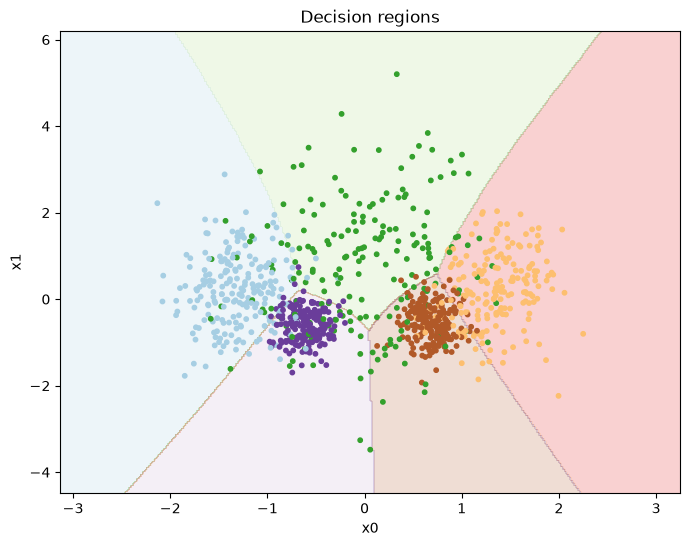

Best Learning Rate: 0.2
Best Epochs: 1500
Best Hidden Size: 20
Best Training Accuracy: 0.843
Best Validation Accuracy: 0.882
Previous Softmax Accuracy: 0.848
Accuracy Difference: 0.034


In [ ]:
# Your code here

#My own code

#Multi-class Neural Network

class MLPMultiClass(MLPBinaryLinRegClass):
    def __init__(self, bias=-1, dim_hidden=6):
        super().__init__(bias=bias, dim_hidden=dim_hidden)
        self.classes = None
        self.history = []

    def forward(self, X):
        hidden = self.activ(X @ self.weights1)
        hidden_outs = add_bias(hidden, self.bias)
        outputs = softmax(hidden_outs @ self.weights2)
        return hidden_outs, outputs

    def fit(self, X_train, t_train, lr=0.1, epochs=1000):
        N, D = X_train.shape
        self.classes = np.unique(t_train)
        n_classes = len(self.classes)

        #One-hot encoding
        T = (t_train[:, None] == self.classes).astype(int)

        #Initialize the weights
        self.weights1 = (np.random.rand(D + 1, self.dim_hidden) * 2 - 1) / np.sqrt(D)
        self.weights2 = (np.random.rand(self.dim_hidden + 1, n_classes) * 2 - 1) / np.sqrt(self.dim_hidden)
        X_train_bias = add_bias(X_train, self.bias)
        self.history = []

        for epoch in range(epochs):
            #Forward
            hidden_outs, outputs = self.forward(X_train_bias)

            #Backpropagation
            out_deltas = outputs - T
            hiddenact_deltas = (out_deltas @ self.weights2[1:, :].T) * self.activ_diff(hidden_outs[:, 1:])

            #Gradient descent
            self.weights2 -= lr * hidden_outs.T @ out_deltas / N
            self.weights1 -= lr * X_train_bias.T @ hiddenact_deltas / N

            #Training Loss
            probabilities = self.forward(X_train_bias)[1]
            loss = multiclass_cross_entropy(T, probabilities) / N
            self.history.append(loss)

        return self

    def predict_probability(self, X):
        outputs = self.forward(add_bias(X, self.bias))[1]
        return outputs

    def predict(self, X):
        probabilities = self.predict_probability(X)
        predictions = np.argmax(probabilities, axis=1)
        return self.classes[predictions]



#Test Multi-class MLP

np.random.seed(2024)

MLP_multi = MLPMultiClass(bias=-1, dim_hidden=6)
MLP_multi.fit(X_train_scaled, t_multi_train, lr=0.1, epochs=1000)

print("Training Accuracy:", accuracy(MLP_multi.predict(X_train_scaled), t_multi_train))
print("Validation Accuracy:", accuracy(MLP_multi.predict(X_val_scaled), t_multi_val))
print("First 5 Predictions:", MLP_multi.predict(X_val_scaled[:5]))
print("First 5 Probabilities:", MLP_multi.predict_probability(X_val_scaled[:5]))



#Check probabilities

probabilities = MLP_multi.predict_probability(X_val_scaled[:5])

print("Probability sums:", np.sum(probabilities, axis=1))
print("Weights1 Shape:", MLP_multi.weights1.shape)
print("Weights2 Shape:", MLP_multi.weights2.shape)

#Different learning rates

learning_rates = [0.05, 0.1, 0.2]

for lr in learning_rates:
    np.random.seed(2024)
    MLP = MLPMultiClass(bias=-1, dim_hidden=6)
    MLP.fit(X_train_scaled, t_multi_train, lr=lr, epochs=1000)

    val_accuracy = accuracy(MLP.predict(X_val_scaled), t_multi_val)
    print(f"Learning Rate: {lr}, Accuracy: {val_accuracy:.4f}")


#Different Epochs

epochs_list = [500, 1000, 1500]

for epochs in epochs_list:
    np.random.seed(2024)
    MLP = MLPMultiClass(bias=-1, dim_hidden=6)
    MLP.fit(X_train_scaled, t_multi_train, lr=0.1, epochs=epochs)

    val_accuracy = accuracy(MLP.predict(X_val_scaled), t_multi_val)
    print(f"Epochs: {epochs}, Accuracy: {val_accuracy:.4f}")


#Different Hidden sizes

hidden_sizes = [6, 12, 20]

for hidden in hidden_sizes:
    np.random.seed(2024)
    MLP = MLPMultiClass(bias=-1, dim_hidden=hidden)
    MLP.fit(X_train_scaled, t_multi_train, lr=0.1, epochs=1000)

    val_accuracy = accuracy(MLP.predict(X_val_scaled), t_multi_val)
    print(f"Hidden Size: {hidden}, Accuracy: {val_accuracy:.4f}")


#Find the best Validation Accuracy

best_accuracy = 0
best_LR = None
best_EPOCHS = None
best_HIDDEN = None
best_MLP = None

for lr in learning_rates:
    for epochs in epochs_list:
        for hidden in hidden_sizes:
            np.random.seed(2024)
            MLP = MLPMultiClass(bias=-1, dim_hidden=hidden)
            MLP.fit(X_train_scaled, t_multi_train, lr=lr, epochs=epochs)

            val_accuracy = accuracy(MLP.predict(X_val_scaled), t_multi_val)
            print(f"LR: {lr}, Epochs: {epochs}, Hidden: {hidden}, Accuracy: {val_accuracy:.4f}")

            if val_accuracy > best_accuracy:
                best_accuracy = val_accuracy
                best_LR = lr
                best_EPOCHS = epochs
                best_HIDDEN = hidden
                best_MLP = MLP

print("Best Learning Rate:", best_LR)
print("Best Epochs:", best_EPOCHS)
print("Best Hidden Size:", best_HIDDEN)
print("Best Validation Accuracy:", best_accuracy)


#Plot the best Decision Boundaries

plot_decision_regions(X_train_scaled, t_multi_train, best_MLP)
plt.show()



print("Best Learning Rate:", best_LR)
print("Best Epochs:", best_EPOCHS)
print("Best Hidden Size:", best_HIDDEN)
print("Best Training Accuracy:", accuracy(best_MLP.predict(X_train_scaled), t_multi_train))
print("Best Validation Accuracy:", best_accuracy)
print("Previous Softmax Accuracy:", 0.848)
print("Accuracy Difference:", round(best_accuracy - 0.848, 4))






#Conclusion

The best validation accuracy is 0.882

The best learning rate is 0.2

The best number of epochs is 1500

The best hidden size is 20

The MLP performs better than the previous Softmax Logistic Regression

The validation accuracy improved from 0.848 to 0.882

Increasing the hidden size generally improved the accuracy

More epochs and a higher learning rate generally improved the results

The MLP can learn non-linear decision boundaries


The decision boundaries separate the five classes reasonably well

The MLP learns some non-linear decision boundaries

Some points are misclassified where the classes overlap

# Part III: Final testing
We can now perform a final testing on the held-out test set we created in the beginning.

## Binary task (X, t2)
Consider the linear regression classifier, the logistic regression classifier and the multi-layer network with the best settings you found. Train each of them on the training set and evaluate on the held-out test set, but also on the validation set and the training set. Report the performance in a 3 by 3 table.

Comment on what you see. How do the three different algorithms compare? Also, compare the results between the different dataset splits. In cases like these, one might expect slightly inferior results on the held-out test data compared to the validation and training data. Is this the case? 

Also report precision and recall for class 1.

In [ ]:
# Your code here

#My own code

#Binary Task

#Linear Regression Classifier
CL_linear = NumpyLinRegClass()
CL_linear.fit(X_train_scaled, t2_train, lr=0.05, epochs=500)

#Logistic Regression Classifier
CL_logistic = NumpyLogRegClassExtended()
CL_logistic.fit(X_train_scaled, t2_train, learning_rate=0.01, epochs=1000, X_val=X_val_scaled, t_val=t2_val, tol=0.001)

#Multi-layer Neural Network
np.random.seed(2024)
CL_mlp = ImprovedMLPBinaryClassD(bias=-1, dim_hidden=6)
CL_mlp.fit(X_train, t2_train, lr=0.2, epochs=1000, X_val=X_val, t_val=t2_val, tol=0.0001)

#Accuracy Comparison
models = [("Linear Regression", CL_linear, True), ("Logistic Regression", CL_logistic, True), ("MLP", CL_mlp, False)]

print(f"{'Model':<25} {'Train':<10} {'Validation':<12} {'Test':<10}")

for name, model, scaled in models:
    X_tr = X_train_scaled if scaled else X_train
    X_v = X_val_scaled if scaled else X_val
    X_te = scaler.transform(X_test) if scaled else X_test

    train_acc = accuracy(model.predict(X_tr), t2_train)
    val_acc = accuracy(model.predict(X_v), t2_val)
    test_acc = accuracy(model.predict(X_te), t2_test)

    print(f"{name:<25} {train_acc:<10.4f} {val_acc:<12.4f} {test_acc:<10.4f}")



#Precision and Recall for Class 1

for name, model, scaled in models:
    X_te = scaler.transform(X_test) if scaled else X_test
    predictions = model.predict(X_te)

    TP = np.sum((predictions == 1) & (t2_test == 1))
    FP = np.sum((predictions == 1) & (t2_test == 0))
    FN = np.sum((predictions == 0) & (t2_test == 1))

    precision = TP / (TP + FP) if TP + FP > 0 else 0
    recall = TP / (TP + FN) if TP + FN > 0 else 0

    print(f"{name}: Precision = {precision:.4f}, Recall = {recall:.4f}")






Model                     Train      Validation   Test      
Linear Regression         0.7210     0.7600       0.7200    
Logistic Regression       0.7190     0.7620       0.7240    
MLP                       0.8320     0.8520       0.8220    
Linear Regression: Precision = 0.6492, Recall = 0.6294
Logistic Regression: Precision = 0.6561, Recall = 0.6294
MLP: Precision = 0.7368, Recall = 0.8528


#Conclusion

The MLP has the best test accuracy of 0.822

Logistic Regression achieves 0.724

Linear Regression achieves 0.720

The test accuracy is lower than the validation accuracy for all three models

The MLP performs better than the two linear classifiers

The MLP also has the highest precision and recall for class 1

The MLP precision is 0.7368

The MLP recall is 0.8528

There is no clear evidence of severe overfitting

## Multi-class task (X, t_multi)

Compare the three multi-class classifiers, the one-vs-rest and the multinomial logistic regression from part one and the multi-class neural network from part two. Evaluate on test, validation and training set as above.

Comment on the results.

In [ ]:
# Your code here



#My own code

#Multi-class Task

#One-vs-Rest Logistic Regression
CL_ovr_final = OneVsRest()
CL_ovr_final.fit(X_train_scaled, t_multi_train, learning_rate=0.1, epochs=500)

#Multinomial Logistic Regression
CL_softmax_final = NumpySoftmaxClass()
CL_softmax_final.fit(X_train_scaled, t_multi_train, learning_rate=0.1, epochs=500)

#Multi-class Neural Network
np.random.seed(2024)
CL_mlp_final = MLPMultiClass(bias=-1, dim_hidden=20)
CL_mlp_final.fit(X_train_scaled, t_multi_train, lr=0.2, epochs=1500)

#Scaling the Test Set
X_test_scaled = scaler.transform(X_test)

#Accuracy Comparison
models_multi = [("One-vs-Rest", CL_ovr_final), ("Softmax", CL_softmax_final), ("Multi-class MLP", CL_mlp_final)]

print(f"{'Model':<25} {'Train':<10} {'Validation':<12} {'Test':<10}")

for name, model in models_multi:
    train_acc = accuracy(model.predict(X_train_scaled), t_multi_train)
    val_acc = accuracy(model.predict(X_val_scaled), t_multi_val)
    test_acc = accuracy(model.predict(X_test_scaled), t_multi_test)

    print(f"{name:<25} {train_acc:<10.4f} {val_acc:<12.4f} {test_acc:<10.4f}")




Model                     Train      Validation   Test      
One-vs-Rest               0.7790     0.8300       0.7760    
Softmax                   0.7960     0.8480       0.7920    
Multi-class MLP           0.8430     0.8820       0.8380    


#Conclusion


The MLP has the best test accuracy of 0.838

Softmax achieves a test accuracy of 0.792

One-vs-Rest achieves a test accuracy of 0.776

The MLP performs better than the two logistic regression classifiers

The test accuracy is lower than the validation accuracy for all three models

There is no clear evidence of severe overfitting

The MLP can learn non-linear relationships between the features

The results show that the MLP performs best on this dataset

Good luck!